# LABORATORIO 3.1: Modelos basados en recurrencia - Regresión lineal.

El objetivo del presente laboratorío es brindar una aproximación computacional a el uso de modelos de regresión lineal para hacer predicciones sencillas a futuro usando datos de series de tiempo. Se busca introducir el concepto de una recurrencia, y como podemos entrenar modelos con estadios previos de la variable de interés. 

Para esto, usaremos datos online de precio de acciones para apple del 2020 al 2024 a una escala diaría. Usamos la libreria *yfinance* para descargarlos, usando el codigo *AAPL* como codigo para acceder a los datos. Quitamos los *NA* para obtener precios y fechas y poder hacer un plot:

[*********************100%***********************]  1 of 1 completed


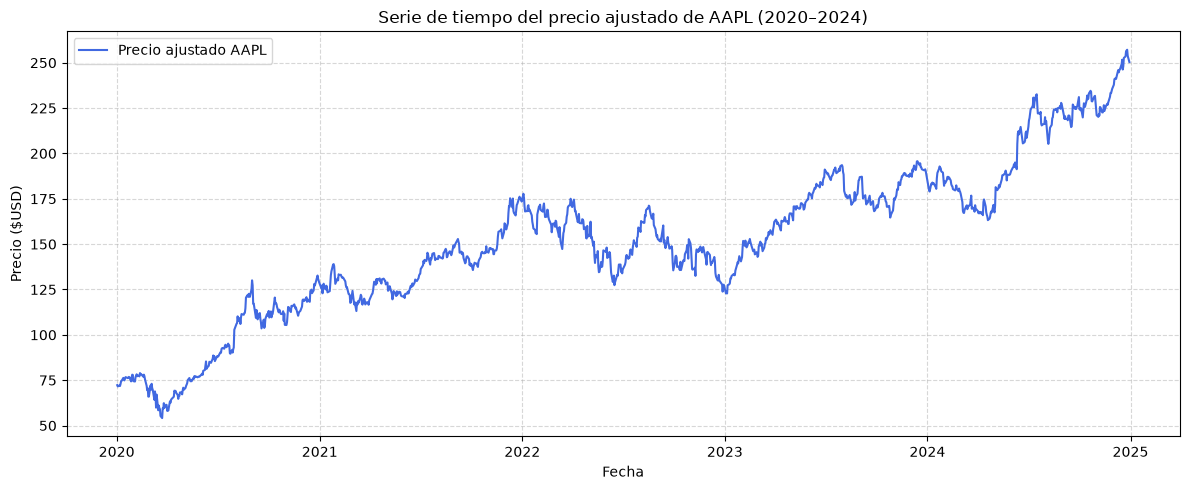

Numero de datos = 1257
(1257,)


In [39]:
import yfinance as yf
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt


# Descargar precios
data = yf.download("AAPL", start="2020-01-01", end="2024-12-31")

# Removemos NA
prices = data['Close'].dropna().values.flatten()
dates = data['Close'].dropna().index

# Graficar la serie
plt.figure(figsize=(12, 5))
plt.plot(dates, prices, label='Precio ajustado AAPL', color='royalblue')
plt.title("Serie de tiempo del precio ajustado de AAPL (2020–2024)")
plt.xlabel("Fecha")
plt.ylabel("Precio ($USD)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
print(f'Numero de datos = {len(prices)}')
print(prices.shape)

Ahora, vamos a crear una función que nos permita partir nuestros datos en ventanas de tiempo. Queremos agarrar los primeros 60 días, que cada día sea un feature, y que la salida sea el día 61. De esta manera, agarramos 2 meses de datos y con base en eso queremos predecir el valor de la acción el siguiente día. Al recorrer esta ventana por toda nuestra serie de tiempo, cada vez que apliquemos la ventana obtendremos una muestra, para al final obtener 60 features de entrada, con distintas muestras, donde cada muestra sale de aplicar la ventana en un lugar diferente de la serie de tiempo.

In [40]:
# Definimos el numero de días en nuestra ventana
window= 60 #días
# Creamos función para obtener todas nuestras muestras (Cada día de la ventana es una feature, y cada ventana con su salida es una muestra)
def create_windows(series, window_size):
    X, y = [], [] #Inicializamos X y y
    for i in range(len(series) - window_size): #Recorremos nuestra serie de tiempo, no vamos hasta al final porque al aplicar ventanas "perdemos" datos.
        X.append(series[i:i+window_size])
        y.append(series[i+window_size])
    return np.array(X), np.array(y)

X, y = create_windows(prices, window_size=window)
print(X.shape, y.shape)

(1197, 60) (1197,)


Tras esto, vamos a agarrar el ultimo 20% de los datos de la serie de tiempo como *test*, y todo el inicio como *train*.

In [41]:
# -----------------------------
# Dividir en train/test (80%-20%)
# -----------------------------
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("Shape X_train:", X_train.shape, "y_train:", y_train.shape)
print("Shape X_test:", X_test.shape, "y_test:", y_test.shape)


Shape X_train: (957, 60) y_train: (957,)
Shape X_test: (240, 60) y_test: (240,)


Con esto, ajustamos una regresión lineal ordinaria y calculamos las métricas de salidas de interes, como el $r^2$ y el $mse$. Podemos observar valores altos, pero hay que tener en cuenta que las series de acciones tienen una fuerte autocorrelación, y que muchas veces no tiene sentido estimar el precio al siguiente día, sino en distintos meses. 

In [42]:
# -----------------------------
# Ajustar modelo lineal
# -----------------------------
model = LinearRegression()
model.fit(X_train, y_train)

# Predicciones
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# -----------------------------
# Métricas
# -----------------------------
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
mse_train = mean_squared_error(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)

print(f"Train R²: {r2_train:.4f} | MSE: {mse_train:.4f}")
print(f"Test R²: {r2_test:.4f} | MSE: {mse_test:.4f}")


Train R²: 0.9930 | MSE: 6.2217
Test R²: 0.9858 | MSE: 9.1973


Por último hacemos un plot para observar como se ven nuestras predicciones.

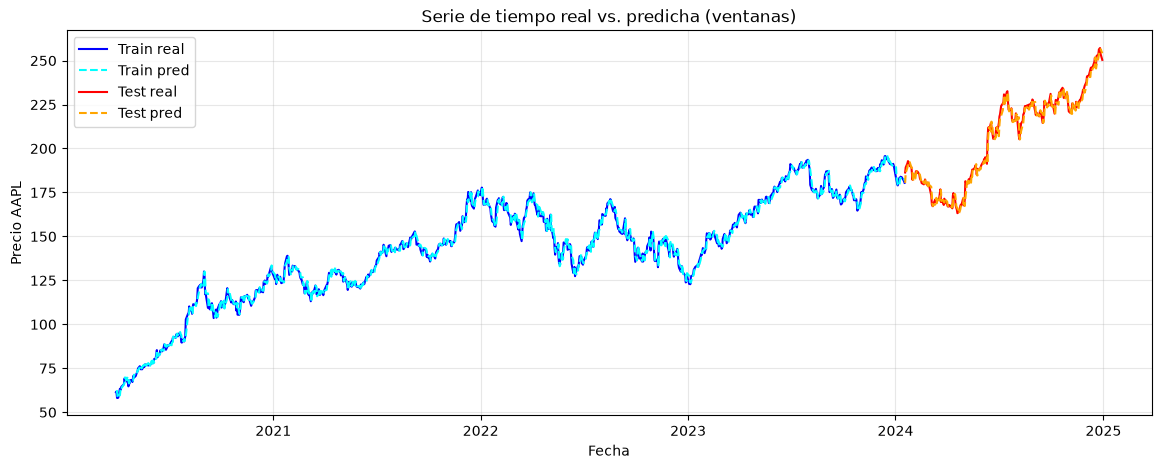

In [43]:
# -----------------------------
# Graficar
# -----------------------------
plt.figure(figsize=(14,5))
plt.plot(dates[window:split+window], y_train, label="Train real", color='blue')
plt.plot(dates[window:split+window], y_pred_train, label="Train pred", color='cyan', linestyle='--')
plt.plot(dates[split+window:], y_test, label="Test real", color='red')
plt.plot(dates[split+window:], y_pred_test, label="Test pred", color='orange', linestyle='--')
plt.xlabel("Fecha")
plt.ylabel("Precio AAPL")
plt.title("Serie de tiempo real vs. predicha (ventanas)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Ahora, aplicaremos el mismo código pero para hacer predicciones no al siguiente día, sino un més despues. Para esto, solo incluimos un *horizonte* de tiempo, que nos dice cuantos días despues es que agarrareos el dato de salida de nuestra ventana de tiempo

In [44]:
horizond=22 #Horizonte
def create_windows_month_ahead(series, window_size, horizon):
    """
    series: numpy array de precios diarios
    window_size: días de la ventana de entrada
    horizon: días hacia adelante para predecir (aprox. 22 días = 1 mes de trading)
    """
    X, y = [], [] #Inicializamos
    for i in range(len(series) - window_size - horizon+1): #Perdemos datos por tamaño de ventana y horizonte
        X.append(series[i:i+window_size])
        y.append(series[i+window_size+horizon-1])  # mismo día del horizonte siguiente
    return np.array(X), np.array(y)
X, y = create_windows_month_ahead(prices, window_size=window,horizon=horizond)
print(X.shape, y.shape)

(1176, 60) (1176,)


Con esto, podemos volver a dividir entre train y test.

In [45]:
# -----------------------------
# Dividir en train/test (80%-20%)
# -----------------------------
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("Shape X_train:", X_train.shape, "y_train:", y_train.shape)
print("Shape X_test:", X_test.shape, "y_test:", y_test.shape)


Shape X_train: (940, 60) y_train: (940,)
Shape X_test: (236, 60) y_test: (236,)


Y finalmente ajustamos nuestro modelo. De esta manera podemos observar como el $r^2$ cae bastante, lo que nos indica que para este horizonte de tiempo nuestro modelo no tiene buena capacidad predictiva.

In [46]:
# -----------------------------
# Ajustar modelo lineal
# -----------------------------
model = LinearRegression()
model.fit(X_train, y_train)

# Predicciones
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# -----------------------------
# Métricas
# -----------------------------
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
mse_train = mean_squared_error(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)

print(f"Train R²: {r2_train:.4f} | MSE: {mse_train:.4f}")
print(f"Test R²: {r2_test:.4f} | MSE: {mse_test:.4f}")

Train R²: 0.8604 | MSE: 107.8094
Test R²: 0.5477 | MSE: 296.1638


Al final, hacemos un gráfico de las series de tiempo de train y test y de los resultados de la predicción de nuestro modelo.

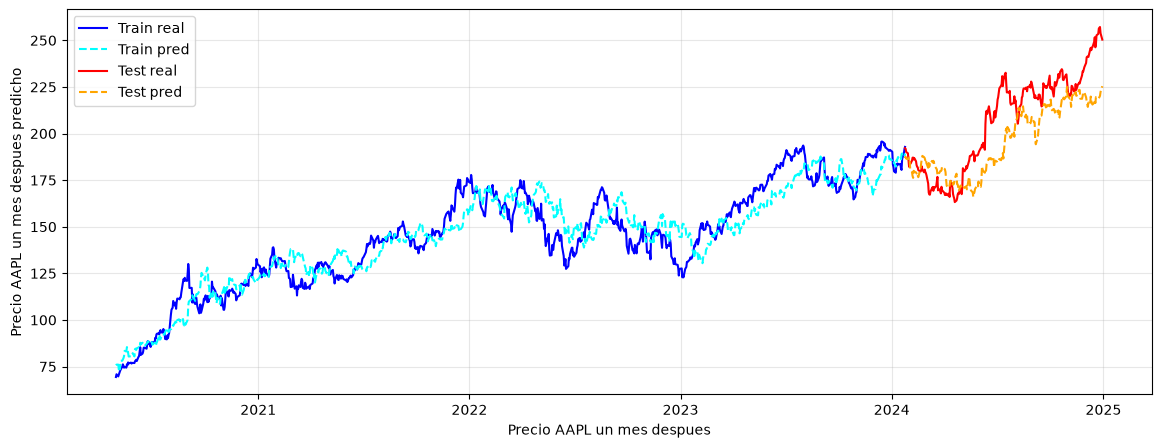

In [47]:

plt.figure(figsize=(14,5))
plt.plot(dates[window+horizond:split+window+horizond],y_train, label="Train real", color='blue')
plt.plot(dates[window+horizond:split+window+horizond],y_pred_train, label="Train pred", color='cyan', linestyle='--')
plt.plot(dates[split+window+horizond-1:],y_test, label="Test real", color='red')
plt.plot(dates[split+window+horizond-1:],y_pred_test, label="Test pred", color='orange', linestyle='--')
plt.xlabel("Precio AAPL un mes despues")
plt.ylabel("Precio AAPL un mes despues predicho")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### QUIZ SEMANA 10:

1. Copie el código en chatGPT o su IA generativa de confianza, y pidale que le explique paso a paso el código. Mencione *3* aprendizajes que haya tenido con la respuesta de su inteligencia artificial generativa de confianza.
2. Elija 5 distintos valores del horizonte de tiempo, y 5 valores distintos para el tamaño de la ventana. Con base en esto, corra los modelos combinando todos estos valores (25 modelos), calcule el $r^{2}$ y haga un heatmap donde en el eje horizontal tenga horizonte de tiempo, en el vertical tenga el tamaño de la ventana, y el color sea el $r^{2}$. ¿Que le dice esto sobre la capacidad predictiva en series de tiempo?


### Punto 1. Tres aprendizajes del laboratorio

**1. Un R² elevado no necesariamente significa que el modelo tenga una buena capacidad predictiva**

Uno de los aprendizajes más importantes fue comprender que obtener un coeficiente de determinación (R²) cercano a 1 no garantiza que el modelo sea capaz de anticipar correctamente el comportamiento futuro de una acción. En el laboratorio, la regresión lineal puede alcanzar un buen rendimiento al predecir precios a corto plazo, pero esto se debe en parte a que los precios de días consecutivos suelen ser muy similares. Por lo tanto, el modelo puede obtener métricas favorables simplemente aprovechando esa continuidad, sin necesariamente aprender a identificar cambios bruscos o tendencias futuras. Esto nos permitió entender la importancia de interpretar las métricas según el contexto del problema y no asumir que un R² alto significa que el modelo sería confiable para tomar decisiones financieras.

**2. La autocorrelación de las series temporales facilita las predicciones a corto plazo**

Aprendí que, a diferencia de otros conjuntos de datos, las observaciones de una serie temporal suelen estar relacionadas con sus valores anteriores. En el caso de los precios de las acciones de Apple, el precio de un día suele estar fuertemente relacionado con el del día anterior. Esta dependencia temporal, conocida como autocorrelación, explica por qué utilizar precios históricos como variables de entrada puede funcionar relativamente bien para predicciones a corto plazo. Sin embargo, también comprendmos que esta relación pierde utilidad a medida que aumenta el horizonte de predicción, ya que existe mayor incertidumbre sobre los cambios que pueden ocurrir en el mercado. Esto ayuda a explicar por qué predecir el precio del siguiente día resulta generalmente más sencillo que estimarlo varias semanas después.

**3. Las ventanas deslizantes generan ejemplos de entrenamiento que comparten gran parte de su información**

Un aspecto interesante del código fue descubrir que las ventanas deslizantes utilizadas para construir los datos de entrenamiento no son independientes entre sí. Por ejemplo, cuando se utiliza una ventana de 60 observaciones, dos ventanas consecutivas comparten 59 valores y solo se diferencian en la observación que sale y la nueva que entra. Esto ocurre porque la función `create_windows()` recorre la serie temporal desplazándose una posición en cada iteración. Aprendimos que este mecanismo permite aprovechar los datos históricos para generar múltiples ejemplos de entrenamiento, pero también produce muestras altamente relacionadas. Por esta razón, es importante respetar el orden cronológico al dividir los conjuntos de entrenamiento y prueba, evitando evaluaciones demasiado optimistas que podrían surgir al mezclar aleatoriamente ventanas con información temporal compartida.

### Punto 2

En este experimento evaluamos cómo influyen el horizonte de predicción y el tamaño de la ventana en el desempeño de una regresión lineal aplicada a la serie de precios de AAPL. Para ello, seleccionamos cinco horizontes  5, 10, 15 , 20 y 25 "días de negociación" junto con el 1, y cinco tamaños de ventana 5, 15, 30, 120 y 150 días, junto con los 60 dias del laboratorio y probamos todas sus combinaciones, dando un total de 36 modelos. En cada caso, la ventana contiene los precios históricos que el modelo usa como entrada, mientras que el horizonte indica cuántos días después del final de esa ventana se encuentra el precio que se busca predecir.

Para cada combinación, transformamos la serie en ejemplos de entrada y salida, dividimos los datos cronológicamente usando el 80 % inicial para entrenamiento y el 20 % final para prueba, y ajustamos una regresión lineal. Luego calculamos el \(R^2\) sobre los datos de prueba y lo guardamos en una matriz. Finalmente, mostramos esos resultados en una tabla y un mapa de calor, donde las filas corresponden al tamaño de la ventana, las columnas al horizonte y el color representa el \(R^2\). Así podemos comparar qué combinaciones predicen mejor los datos futuros y observar si el desempeño cambia al usar más historial o al intentar predecir más lejos.

R² en el conjunto de prueba:


Horizonte de predicción,1 días,5 días,10 días,15 días,20 días,25 días
Tamaño de ventana,,,,,,
5 días,0.9868,0.9299,0.8518,0.7714,0.6882,0.5984
15 días,0.9868,0.9298,0.8504,0.7680,0.6824,0.5880
30 días,0.9866,0.9291,0.8447,0.7527,0.6488,0.5344
60 días,0.9858,0.9195,0.8203,0.7136,0.5977,0.4734
120 días,0.9849,0.9146,0.8080,0.6963,0.5680,0.4100
150 días,0.9839,0.9142,0.8085,0.7018,0.5992,0.4700


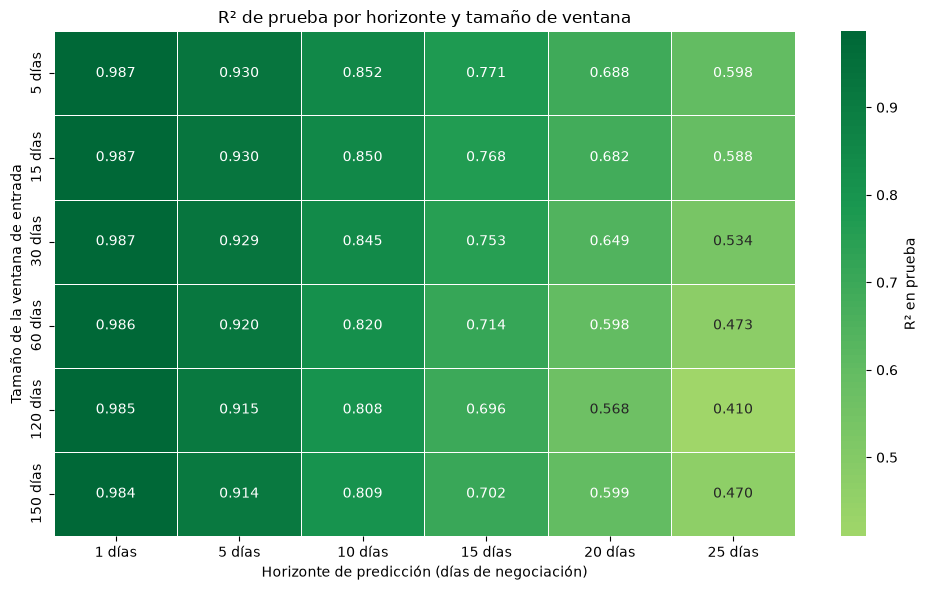

Mejor R²: 0.9868 (ventana=5, horizonte=1 días)
Menor R²: 0.4100 (ventana=120, horizonte=25 días)


In [49]:
import seaborn as sns
import pandas as pd


horizons = [1, 5, 10, 15, 20, 25]
window_sizes = [5, 15, 30, 60, 120, 150]

r2_results = np.zeros((len(window_sizes), len(horizons)))

for i, window_size in enumerate(window_sizes):
    for j, horizon in enumerate(horizons):
        X_grid, y_grid = create_windows_month_ahead(
            prices,
            window_size=window_size,
            horizon=horizon
        )

        # Mantener el orden temporal: 80% inicial para train, 20% final para test
        split_idx = int(len(X_grid) * 0.8)
        X_train_grid, X_test_grid = X_grid[:split_idx], X_grid[split_idx:]
        y_train_grid, y_test_grid = y_grid[:split_idx], y_grid[split_idx:]

        model_grid = LinearRegression()
        model_grid.fit(X_train_grid, y_train_grid)
        y_pred_grid = model_grid.predict(X_test_grid)

        r2_results[i, j] = r2_score(y_test_grid, y_pred_grid)

# Tabla: filas = tamaños de ventana; columnas = horizontes
r2_table = pd.DataFrame(
    r2_results,
    index=[f"{w} días" for w in window_sizes],
    columns=[f"{h} días" for h in horizons]
)
r2_table.index.name = "Tamaño de ventana"
r2_table.columns.name = "Horizonte de predicción"

print("R² en el conjunto de prueba:")
display(r2_table.round(4))

# Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    r2_table,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "R² en prueba"}
)
plt.title("R² de prueba por horizonte y tamaño de ventana")
plt.xlabel("Horizonte de predicción (días de negociación)")
plt.ylabel("Tamaño de la ventana de entrada")
plt.tight_layout()
plt.show()

# Identificar las combinaciones con mejor y peor R²
mejor_i, mejor_j = np.unravel_index(np.argmax(r2_results), r2_results.shape)
peor_i, peor_j = np.unravel_index(np.argmin(r2_results), r2_results.shape)

print(
    f"Mejor R²: {r2_results[mejor_i, mejor_j]:.4f} "
    f"(ventana={window_sizes[mejor_i]}, horizonte={horizons[mejor_j]} días)"
)
print(
    f"Menor R²: {r2_results[peor_i, peor_j]:.4f} "
    f"(ventana={window_sizes[peor_i]}, horizonte={horizons[peor_j]} días)"
)

### Conclusión del punto 2

Los resultados muestran que el R² de prueba disminuye al aumentar el horizonte de predicción en todas las ventanas evaluadas. La mejor combinación identificada fue una **ventana de 5 días con un horizonte de 1 día**, con **R² = 0.9868**; aunque la ventana de 15 días alcanza el mismo valor al redondear a cuatro decimales, el código identifica la de 5 días como la de mayor R². La peor combinación fue una **ventana de 120 días con un horizonte de 25 días**, con **R² = 0.4100**. Esto muestra que, en esta evaluación, el modelo logra ajustarse mejor a los precios observados cuando predice a corto plazo y pierde capacidad para explicar su variación al intentar anticiparlos más lejos.

Sin embargo, **tener un buen R² no implica por sí solo que un modelo sea mejor para predecir el mercado**: indica que sus predicciones se ajustan bien a los datos evaluados según esta métrica. En particular, los precios de días consecutivos suelen ser similares, por lo que un R² alto a un día puede reflejar esa continuidad sin demostrar que el modelo anticipe cambios de tendencia. Para evaluar su utilidad predictiva también sería necesario revisar los errores y compararlo con una predicción sencilla, como usar el último precio conocido, además de comprobar su desempeño en otros períodos.

Inicialmente, uno podría pensar que la ventana más amplia tendría el mejor desempeño porque dispone de más información del pasado. No obstante, **la ventana de 5 días obtuvo el mayor R² en todos los horizontes evaluados**. Una posible explicación es que la información más reciente sea suficiente para capturar la dinámica de estos datos, mientras que incorporar precios más antiguos añada ruido o información menos relevante, que actúe como una distracción para el modelo. Además, una ventana más grande introduce más variables y deja menos ejemplos disponibles para entrenar, lo que puede dificultar la generalización. Estas son posibles explicaciones del resultado, no causas demostradas por el mapa de calor.

Un resultado sorprendente es que **la peor combinación no fue la ventana de 150 días al predecir 25 días adelante, sino la ventana anterior, de 120 días**: sus R² fueron **0.4700 y 0.4100**, respectivamente. Por tanto, la caída del desempeño al ampliar la ventana no es estrictamente progresiva. La recuperación con 150 días podría deberse a información adicional útil, pero también a la variabilidad del período evaluado. Además, como cada combinación genera una cantidad distinta de muestras y se divide de manera independiente en 80 % para entrenamiento y 20 % para prueba, los períodos de prueba no son exactamente iguales. Con estos resultados no podemos determinar si la diferencia es producto de la suerte o de un patrón estable; habría que repetir la evaluación en varios períodos, usando fechas de prueba comunes, para comprobarlo. En conjunto, el experimento muestra que más historia no garantiza mejores predicciones y que el tamaño de la ventana debe evaluarse junto con el horizonte y la estabilidad de los resultados.
